# Clima de las regiones de la Tierra y de los sitios de Marte (v0.1)
**NASA Space Apps Challenge 2026** · Capa de clima para comparar cada sitio de Marte con las regiones candidatas y los análogos
conocidos de la Tierra.

| Lado | Datos | Qué se mide |
|---|---|---|
| Tierra | MERRA-2 2014–2023 (ya en Drive, de `EDA_analogos_v1.3`) + MERRA-2 `M2SMNXSLV` (máximas y mínimas diarias) | temperatura media, del mes más frío y del más cálido, mínima de las noches del mes más frío, oscilación diaria, precipitación |
| Marte | Reanálisis MACDA v2.0 (Oxford/Open University, observaciones de MCS) en ARCO-Mars (Hugging Face) | temperatura de la superficie cada 2 horas durante 5 años marcianos (MY 29–33), en una rejilla de 5° |
| Luna | — | no tiene atmósfera: su temperatura depende de la iluminación, no del clima. Solo se guarda el clima de las regiones de la Tierra del perfil Luna, como dato informativo |

**Comparación por percentiles relativos**: ningún lugar de la Tierra es tan frío como Marte (media de unos −60 °C), así que no se
comparan valores absolutos. Cada sitio de Marte se coloca en su percentil dentro de los sitios de Marte (p. ej. «entre el 10 % más frío»)
y cada región de la Tierra en su percentil dentro de las regiones de la Tierra; se emparejan los que ocupan el mismo puesto relativo.
Distancia de clima = media de las diferencias de percentil (0 a 1) en 4 medidas: temperatura media, mínima del mes más frío,
amplitud anual y oscilación diaria. Se combina con la distancia de topografía de `topografia_sitios_v1`.

**Cambio respecto a v0**: la Mars Climate Database no respondía desde Colab (la conexión no llegaba a abrirse), así que Marte sale
del reanálisis MACDA, que se lee por trozos sin descargar el archivo entero (216 GB).

**Por tandas**: la descarga de MERRA-2 (120 archivos pequeños) y la lectura de MACDA (unos 35 trozos de 100 soles) se guardan uno a uno
en Drive y cada ejecución se para a los `MAX_MINUTOS`. **Si al final pone «⏸ Quedan…», vuelve a ejecutar el notebook**: sigue donde lo dejó.

## 0. Instalación

In [12]:
!pip install -q earthaccess zarr

## 1. Configuración

In [13]:
import os, re, gc, json, time, glob, datetime, unicodedata
from urllib.parse import urljoin
import numpy as np, pandas as pd, requests, xarray as xr
import matplotlib.pyplot as plt
import earthaccess
from shapely import contains_xy
from shapely.geometry import shape, Point
from shapely import affinity
from IPython.display import display
from google.colab import drive, userdata

drive.mount("/content/drive")
for raiz in ["/content/drive/MyDrive", "/content/drive/My Drive"]:
    if os.path.isdir(raiz):
        break
BASE = f"{raiz}/Hackathon Nasa"
VERSION = "clima_v0"   # v0.1 del notebook: misma capa, Marte desde MACDA
RES, WEB = f"{BASE}/04_resultados/{VERSION}", f"{BASE}/06_web/{VERSION}"
CACHE_M2 = f"{BASE}/03_datos/cache_api/clima/merra2_diaria"
CACHE_MACDA = f"{BASE}/03_datos/cache_api/clima/macda"
TMP = "/content/tmp/clima"
for d in (RES, WEB, CACHE_M2, CACHE_MACDA, TMP):
    os.makedirs(d, exist_ok=True)

MAX_MINUTOS = 40                       # tiempo máximo por ejecución (vuelve a ejecutar para seguir)
ANIOS = range(2014, 2024)              # mismo periodo que el índice de Marte v1.3
GRADIENTE_K_KM = 6.5                   # corrección de temperatura por altitud (celda de 50 km → altura real del lugar)
RADIO_ANALOGO_KM = 10
MACDA = "hf://datasets/ananyo01/ARCO-MACDA/macda_combined.zarr"   # ARCO-Mars (Zarr en Hugging Face)
ANIOS_MARTE = range(29, 34)            # años marcianos 29–33: era MCS, sin tormentas globales de polvo (MY28 y MY34 sí las tuvieron)
BLOQUE = 1200                          # pasos de tiempo por trozo (100 soles, 12 MB)
MEDIDAS = ["t_media", "t_min", "amplitud_anual", "osc_diaria"]   # las que entran en la comparación
UMBRAL_PARECIDO = 0.2
T0 = time.time()
minutos = lambda: (time.time() - T0) / 60

FIGURAS = f"{RES}/figuras"; os.makedirs(FIGURAS, exist_ok=True)
_mostrar = getattr(plt, "_show_original", plt.show); plt._show_original = _mostrar
_n_fig = [0]
def _mostrar_y_guardar(*a, **k):
    fig = plt.gcf()
    if fig.axes:
        _n_fig[0] += 1
        titulo = next((ax.get_title() for ax in fig.axes if ax.get_title()), "figura")
        slug = re.sub(r"[^a-zA-Z0-9]+", "_", unicodedata.normalize("NFKD", titulo).encode("ascii", "ignore").decode()).strip("_").lower()[:50]
        fig.savefig(f"{FIGURAS}/fig_{_n_fig[0]:02d}_{slug}.png", dpi=80, bbox_inches="tight")
    _mostrar(*a, **k)
plt.show = _mostrar_y_guardar

os.environ["EARTHDATA_USERNAME"] = userdata.get("EARTHDATA_USERNAME")
os.environ["EARTHDATA_PASSWORD"] = userdata.get("EARTHDATA_PASSWORD")
auth = earthaccess.login(strategy="environment")
SESION = earthaccess.get_requests_https_session()
entrada = json.load(open(f"{BASE}/06_web/manifest.json", encoding="utf-8"))
print("Earthdata:", auth.authenticated)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Earthdata: True


## 2. Tierra: regiones candidatas y análogos conocidos
Las mismas que en `topografia_v1` (mismos `region_id`). Cada una se asigna a las celdas de MERRA-2 (0,5° × 0,625°) cuyo centro cae
dentro; los análogos (círculo de 10 km) y las regiones muy pequeñas usan la celda más cercana.

In [14]:
def circulo_grados(lon, lat, radio_km):
    rlat = radio_km / 111.32
    return affinity.scale(Point(lon, lat).buffer(rlat, 64), xfact=1 / max(np.cos(np.radians(lat)), 0.05), yfact=1)

filas = []
for cuerpo in ["luna", "marte"]:
    info = entrada["cuerpos"][cuerpo]
    for ft in json.load(open(f"{BASE}/06_web/{info['carpeta']}/regiones.geojson", encoding="utf-8"))["features"]:
        p = ft["properties"]
        filas.append({"region_id": p["id"], "cuerpo": cuerpo, "tipo": "region_candidata", "region": p.get("region"), "geom": shape(ft["geometry"])})
    for ft in json.load(open(f"{BASE}/06_web/{info['carpeta']}/analogos.geojson", encoding="utf-8"))["features"]:
        p = ft["properties"]
        ok = (p.get("tipo") in ("analogo_luna", "impacto")) if cuerpo == "luna" else (p.get("verificacion") == "verificada")
        if not ok or not ft.get("geometry"):
            continue
        lon, lat = ft["geometry"]["coordinates"][:2]
        slug = re.sub(r"[^a-z0-9]+", "-", unicodedata.normalize("NFKD", p["nombre"]).encode("ascii", "ignore").decode().lower()).strip("-")[:40]
        filas.append({"region_id": f"analogo-{cuerpo}-{slug}", "cuerpo": cuerpo, "tipo": "analogo_conocido", "region": p["nombre"],
                      "geom": circulo_grados(lon, lat, RADIO_ANALOGO_KM)})
ent = pd.DataFrame(filas)

# Altura real de cada lugar (media de ASTER a 30 m, de topografia_v1) para corregir la temperatura de la celda
ruta_t1 = f"{BASE}/06_web/topografia_v1/topografia.json"
topo1 = json.load(open(ruta_t1, encoding="utf-8"))["regiones"] if os.path.exists(ruta_t1) else {}
ent["elev_real_m"] = ent.region_id.map(lambda r: (topo1.get(r) or {}).get("elev_media_m"))

clima_v13 = xr.open_dataset(f"{BASE}/03_datos/procesados/clima_merra2_2014_2023.nc").load()
print("Variables del clima de v1.3:", list(clima_v13.data_vars))
LAT, LON = clima_v13.lat.values, clima_v13.lon.values
LL, LA = np.meshgrid(LON, LAT)
celdas = {}
for r in ent.itertuples():
    dentro = contains_xy(r.geom, LL, LA)
    if dentro.any():
        celdas[r.region_id] = np.argwhere(dentro)
    else:
        c = r.geom.centroid
        celdas[r.region_id] = np.array([[np.abs(LAT - c.y).argmin(), np.abs(((LON - c.x + 180) % 360) - 180).argmin()]])
ent["n_celdas"] = ent.region_id.map(lambda r: len(celdas[r]))
print(f"{len(ent)} lugares de la Tierra:", ent.groupby(["cuerpo", "tipo"]).size().to_dict())

Variables del clima de v1.3: ['T_media', 'T_frio', 'T_calido', 'P_anual', 'tierra', 'hielo', 'elevacion', 'presion_aprox', 'ndvi_max', 'frac_desnudo']
56 lugares de la Tierra: {('luna', 'analogo_conocido'): 7, ('luna', 'region_candidata'): 20, ('marte', 'analogo_conocido'): 8, ('marte', 'region_candidata'): 21}


## 3. Tierra: temperatura media, del mes más frío y del más cálido, y precipitación (MERRA-2, ya calculado en v1.3)
Se corrige por altitud: la celda de MERRA-2 tiene la altura media de 50 km, que puede diferir mucho del lugar
(Mauna Kea, Tso Kar). Corrección: −6,5 °C por cada km que el lugar está por encima de la celda.

In [15]:
def en_celdas(da, rid):
    ij = celdas[rid]
    return float(np.nanmean(da.values[ij[:, 0], ij[:, 1]]))

a_celsius = (lambda v: v - 273.15) if float(clima_v13["T_media"].max()) > 150 else (lambda v: v)
tierra = ent.drop(columns="geom").copy()
for var, col in (("T_media", "t_media"), ("T_frio", "t_frio"), ("T_calido", "t_calido")):
    tierra[col] = [a_celsius(en_celdas(clima_v13[var], r)) for r in tierra.region_id]
tierra["precip_mm"] = [en_celdas(clima_v13["P_anual"], r) for r in tierra.region_id] if "P_anual" in clima_v13 else np.nan
tierra["elev_celda_m"] = [en_celdas(clima_v13["elevacion"], r) for r in tierra.region_id]
tierra["correccion_c"] = (-GRADIENTE_K_KM * (tierra.elev_real_m.astype(float) - tierra.elev_celda_m) / 1000).fillna(0).round(1)
for col in ("t_media", "t_frio", "t_calido"):
    tierra[col] = (tierra[col] + tierra.correccion_c).round(1)
tierra["amplitud_anual"] = (tierra.t_calido - tierra.t_frio).round(1)
display(tierra[["region_id", "region", "elev_celda_m", "elev_real_m", "correccion_c", "t_media", "t_frio", "t_calido", "precip_mm"]].round(1))

,region_id,region,elev_celda_m,elev_real_m,correccion_c,t_media,t_frio,t_calido,precip_mm
0,luna-1,"Afar, Etiopía",362.0,290,0.5,30.8,26.1,35.1,334.5
1,luna-2,"Gobernacion de Rif Dimashq, Siria",786.6,803,-0.1,18.8,7.0,29.3,102.7
2,luna-3,"Provincia de Medina, Arabia Saudita",1304.9,1105,1.3,24.6,13.4,33.8,38.9
3,luna-4,"Afar, Etiopía",477.5,477,0.0,29.7,25.0,34.6,441.8
4,luna-5,"Condado de Marsabit, Kenia",569.4,482,0.6,29.8,28.5,31.3,214.9
5,luna-6,"Provincia de La Meca, Arabia Saudita",1291.6,1254,0.2,25.7,17.6,32.5,74.4
6,luna-7,Islandia,801.8,648,1.0,-1.9,-6.6,3.7,875.2
7,luna-8,"Afar, Etiopía",564.8,466,0.6,29.7,25.2,34.1,545.8
8,luna-9,"Provincia de Tabuk, Arabia Saudita",1295.0,1424,-0.8,19.8,8.6,29.2,29.4
9,luna-10,"Tibesti, Chad",1666.8,1681,-0.1,20.2,11.7,26.5,51.5


## 4. Tierra: oscilación diaria (MERRA-2 `M2SMNXSLV`, medias mensuales de las máximas y mínimas diarias, 2014–2023)
120 archivos mensuales: se descarga uno, se extraen los valores de los lugares, se borra y se guarda un resumen pequeño en Drive.

In [16]:
meses = [f"{a}{m:02d}" for a in ANIOS for m in range(1, 13)]
hecho = lambda ym: os.path.exists(f"{CACHE_M2}/{ym}.npz")
pendientes = [ym for ym in meses if not hecho(ym)]
print(f"Meses ya procesados: {len(meses) - len(pendientes)}/{len(meses)}")
if pendientes:
    granulos = earthaccess.search_data(short_name="M2SMNXSLV", version="5.12.4",
                                       temporal=(f"{min(ANIOS)}-01-01", f"{max(ANIOS)}-12-31"))
    enlaces = {}
    for g in granulos:
        for u in g.data_links():
            m = re.search(r"\.(\d{6})\.nc4$", u)
            if m:
                enlaces[m.group(1)] = u
    print(f"Granulos encontrados: {len(enlaces)}")
    for k, ym in enumerate(pendientes):
        if minutos() > MAX_MINUTOS:
            break
        if ym not in enlaces:
            print("  ⚠ falta el mes", ym); continue
        ruta = f"{TMP}/{ym}.nc4"
        try:
            with SESION.get(enlaces[ym], stream=True, timeout=300) as r:
                r.raise_for_status()
                with open(ruta, "wb") as f:
                    for t in r.iter_content(1 << 22):
                        f.write(t)
            with xr.open_dataset(ruta) as ds:
                tmax = ds["T2MMAX"].isel(time=0).values; tmin = ds["T2MMIN"].isel(time=0).values
                assert tmax.shape == LL.shape, f"Rejilla distinta de la de v1.3: {tmax.shape}"
            vals = {rid: (np.nanmean(tmax[ij[:, 0], ij[:, 1]]), np.nanmean(tmin[ij[:, 0], ij[:, 1]])) for rid, ij in celdas.items()}
            np.savez(f"{CACHE_M2}/{ym}.npz", ids=np.array(list(vals)), tmax=np.array([v[0] for v in vals.values()]),
                     tmin=np.array([v[1] for v in vals.values()]))
            del tmax, tmin
        except Exception as e:
            print(f"  ⚠ {ym}: {e!r} (se reintentará)")
        finally:
            if os.path.exists(ruta): os.remove(ruta)
            gc.collect()
        if k % 20 == 0:
            print(f"  {ym} · {minutos():.0f} min")
FALTAN_M2 = [ym for ym in meses if not hecho(ym)]

# Climatología mensual (media de los 10 años por mes) de máximas y mínimas diarias
acum = {}
for ym in meses:
    if not hecho(ym):
        continue
    d = np.load(f"{CACHE_M2}/{ym}.npz")
    for rid, mx, mn in zip(d["ids"], d["tmax"], d["tmin"]):
        acum.setdefault(str(rid), {}).setdefault(int(ym[4:]), []).append((mx, mn))
def resumen_diario(rid):
    if rid not in acum:
        return np.nan, np.nan
    clim = {m: np.mean(v, axis=0) for m, v in acum[rid].items()}
    osc = np.mean([mx - mn for mx, mn in clim.values()])
    t_min = min(mn for mx, mn in clim.values()) - 273.15          # mínima diaria media del mes más frío
    return osc, t_min
res = [resumen_diario(r) for r in tierra.region_id]
tierra["osc_diaria"] = [round(o, 1) for o, _ in res]
tierra["t_min"] = [round(t + c, 1) for (_, t), c in zip(res, tierra.correccion_c)]
print("✅ MERRA-2 diario completo." if not FALTAN_M2 else f"⏸ Quedan {len(FALTAN_M2)} meses de MERRA-2: vuelve a ejecutar el notebook.")
tierra.to_csv(f"{RES}/clima_tierra.csv", index=False)
display(tierra[["region", "cuerpo", "tipo", "t_media", "t_min", "amplitud_anual", "osc_diaria", "precip_mm"]])

Meses ya procesados: 120/120
✅ MERRA-2 diario completo.


,region,cuerpo,tipo,t_media,t_min,amplitud_anual,osc_diaria,precip_mm
0,"Afar, Etiopía",luna,region_candidata,30.8,19.700001,9.0,13.600000,334.461535
1,"Gobernacion de Rif Dimashq, Siria",luna,region_candidata,18.8,1.600000,22.3,15.800000,102.652701
2,"Provincia de Medina, Arabia Saudita",luna,region_candidata,24.6,6.200000,20.4,16.100000,38.906014
3,"Afar, Etiopía",luna,region_candidata,29.7,18.000000,9.6,14.100000,441.847235
4,"Condado de Marsabit, Kenia",luna,region_candidata,29.8,21.900000,2.8,13.100000,214.893535
5,"Provincia de La Meca, Arabia Saudita",luna,region_candidata,25.7,9.900000,14.9,16.400000,74.417481
6,Islandia,luna,region_candidata,-1.9,-9.300000,10.3,4.200000,875.228624
7,"Afar, Etiopía",luna,region_candidata,29.7,17.900000,8.9,14.400000,545.757902
8,"Provincia de Tabuk, Arabia Saudita",luna,region_candidata,19.8,2.000000,20.6,16.100000,29.377928
9,"Tibesti, Chad",luna,region_candidata,20.2,3.500000,14.8,16.900000,51.475073


## 5. Marte: reanálisis MACDA (ARCO-Mars)
MACDA combina un modelo del clima de Marte con las temperaturas medidas por Mars Climate Sounder (MRO). Se usa la **temperatura de la
superficie** cada 2 horas (12 valores por sol) en la celda de 5° de cada sitio, durante 5 años marcianos. Se lee por trozos de 100 soles
desde Hugging Face y de cada trozo solo se guardan las celdas de los sitios.

In [17]:
import zarr
try:
    ds_m = xr.open_zarr(MACDA, decode_times=False)
except ValueError as e:
    raise RuntimeError("xarray no reconoce Zarr: Entorno de ejecución → Reiniciar sesión y vuelve a ejecutar el notebook") from e
sitios = json.load(open(f"{BASE}/06_web/sitios_v0/sitios.geojson", encoding="utf-8"))["features"]
marte = [{"id": f["properties"]["id"], "nombre": f["properties"]["nombre"], "tipo": f["properties"]["tipo"],
          "lon": ((f["geometry"]["coordinates"][0] + 180) % 360) - 180, "lat": f["geometry"]["coordinates"][1]}
         for f in sitios if f["properties"]["cuerpo"] == "marte" and f["geometry"]["type"] == "Point"]
LAT_M, LON_M = ds_m.lat.values, ds_m.lon.values
for s in marte:
    s["ilat"] = int(np.abs(LAT_M - s["lat"]).argmin())
    s["ilon"] = int(np.abs(((LON_M - s["lon"] + 180) % 360) - 180).argmin())
ILAT, ILON = np.array([s["ilat"] for s in marte]), np.array([s["ilon"] for s in marte])

anio = np.floor(ds_m["MY_Ls"].values)
idx = np.where(np.isin(anio, list(ANIOS_MARTE)))[0]
assert len(idx), f"No hay datos de los años {list(ANIOS_MARTE)}: años disponibles {np.unique(anio)}"
i0, i1 = int(idx.min()), int(idx.max()) + 1
bloques = [(a, min(a + BLOQUE, i1)) for a in range((i0 // BLOQUE) * BLOQUE, i1, BLOQUE)]
print(f"{len(marte)} sitios en {len(set(zip(ILAT, ILON)))} celdas · años {list(ANIOS_MARTE)}: {i1 - i0} pasos de tiempo en {len(bloques)} trozos")
ruta_b = lambda a: f"{CACHE_MACDA}/bloque_{a:06d}.npz"
for k, (a, b) in enumerate(bloques):
    if os.path.exists(ruta_b(a)):
        continue
    if minutos() > MAX_MINUTOS:
        break
    try:
        trozo = ds_m["tsurf"].isel(time=slice(a, b)).values                    # (tiempo, lat, lon), ~12 MB
        np.savez(ruta_b(a), t=ds_m.time.values[a:b], ls=ds_m["Ls"].values[a:b], my=anio[a:b],
                 tsurf=trozo[:, ILAT, ILON].astype("float32"))
        del trozo; gc.collect()
    except Exception as e:
        print(f"  ⚠ trozo {a}: {e!r} (se reintentará)")
    if k % 5 == 0:
        print(f"  trozo {k + 1}/{len(bloques)} · {minutos():.0f} min")
FALTAN_MARTE = [a for a, b in bloques if not os.path.exists(ruta_b(a))]
print("✅ MACDA completo." if not FALTAN_MARTE else f"⏸ Quedan {len(FALTAN_MARTE)} trozos de MACDA: vuelve a ejecutar el notebook.")

59 sitios en 46 celdas · años [29, 30, 31, 32, 33]: 42636 pasos de tiempo en 36 trozos


HTTP Error 429 thrown while requesting GET https://huggingface.co/datasets/ananyo01/ARCO-MACDA/resolve/main/macda_combined.zarr/Ls/c/339
Rate limited. Waiting 140.0s before retry [Retry 1/5].
HTTP Error 429 thrown while requesting GET https://huggingface.co/datasets/ananyo01/ARCO-MACDA/resolve/main/macda_combined.zarr/Ls/c/338
Rate limited. Waiting 140.0s before retry [Retry 1/5].


  trozo 31/36 · 4 min


HTTP Error 503 thrown while requesting GET https://huggingface.co/datasets/ananyo01/ARCO-MACDA/resolve/main/macda_combined.zarr/tsurf/c/638/0/0
Retrying in 1s [Retry 1/5].
HTTP Error 429 thrown while requesting GET https://huggingface.co/datasets/ananyo01/ARCO-MACDA/resolve/main/macda_combined.zarr/Ls/c/570
Rate limited. Waiting 189.0s before retry [Retry 1/5].
HTTP Error 429 thrown while requesting GET https://huggingface.co/datasets/ananyo01/ARCO-MACDA/resolve/main/macda_combined.zarr/Ls/c/57
Rate limited. Waiting 189.0s before retry [Retry 1/5].


  trozo 36/36 · 10 min
✅ MACDA completo.


In [18]:
clima_m = pd.DataFrame()
if not FALTAN_MARTE:
    partes = [np.load(ruta_b(a)) for a, b in bloques]
    t = np.concatenate([p["t"] for p in partes]); ls = np.concatenate([p["ls"] for p in partes])
    my = np.concatenate([p["my"] for p in partes]); ts = np.concatenate([p["tsurf"] for p in partes])
    sel = np.isin(my, list(ANIOS_MARTE))
    t, ls, ts = t[sel], ls[sel], ts[sel]
    sol = np.floor(t - 1e-6).astype(int)                                   # 12 valores por sol (cada 2 horas)
    filas_m = []
    for j, s in enumerate(marte):
        d = pd.DataFrame({"sol": sol, "ls": ls, "t": ts[:, j]})
        d = d[(d.t > 50) & (d.t < 400)]
        dia = d.groupby("sol").agg(media=("t", "mean"), mx=("t", "max"), mn=("t", "min"), ls=("ls", "mean"), n=("t", "size"))
        dia = dia[dia.n >= 10]                                             # soles completos
        dia["bin"] = (dia.ls // 30).astype(int)                            # «meses» de 30° de Ls
        meses_m = dia.groupby("bin").agg(media=("media", "mean"), mn=("mn", "mean"), mx=("mx", "mean"))
        filas_m.append({"id": s["id"], "nombre": s["nombre"], "tipo": s["tipo"], "lat": s["lat"], "lon": s["lon"],
                        "t_media": dia.media.mean() - 273.15, "t_frio": meses_m.media.min() - 273.15,
                        "t_calido": meses_m.media.max() - 273.15, "amplitud_anual": meses_m.media.max() - meses_m.media.min(),
                        "osc_diaria": (dia.mx - dia.mn).mean(), "t_min": meses_m.mn.min() - 273.15,
                        "t_max": meses_m.mx.max() - 273.15, "soles": len(dia)})
    clima_m = pd.DataFrame(filas_m)
    num = clima_m.select_dtypes("number").columns
    clima_m[num] = clima_m[num].astype(float).round(1)
    clima_m.to_csv(f"{RES}/clima_marte_sitios.csv", index=False)
    display(clima_m.sort_values("t_media")[["nombre", "tipo", "lat", "t_media", "t_min", "t_max", "amplitud_anual", "osc_diaria", "soles"]])

,nombre,tipo,lat,t_media,t_min,t_max,amplitud_anual,osc_diaria,soles
6,Phoenix,aterrizaje_robotico,68.2,-97.8,-124.3,-16.9,75.0,28.5,3343.0
56,Copernicus Crater,exploration_zone,-49.2,-77.5,-127.7,24.2,99.5,61.9,3343.0
55,Arcadia Planitia,exploration_zone,46.2,-75.8,-122.8,-3.7,64.3,73.3,3343.0
2,Viking 2,aterrizaje_robotico,47.6,-75.5,-122.4,-3.3,66.5,72.0,3343.0
43,E. Hellas,exploration_zone,-40.0,-72.1,-126.0,23.6,80.1,74.6,3343.0
52,Acheron Fossae,exploration_zone,39.8,-71.9,-116.4,7.8,33.5,106.1,3343.0
51,Erebus Montes,exploration_zone,39.0,-70.2,-119.7,7.8,39.7,100.7,3343.0
0,Mars 3,aterrizaje_robotico,-45.0,-69.4,-125.2,28.4,79.8,76.9,3343.0
45,Deuteronilus Mensae 2,exploration_zone,41.0,-69.4,-117.4,0.8,49.8,80.4,3343.0
53,Newton Crater,exploration_zone,-40.6,-69.4,-125.2,28.4,79.8,76.9,3343.0


## 6. Comparación por percentiles relativos (Marte ↔ Tierra)
Cada sitio de Marte se compara con las regiones del perfil Marte y los análogos conocidos de Marte. Se usa el percentil (0–100) de cada
medida dentro de su propio planeta. Después se combina con la distancia de topografía (`topografia_sitios_v1`).

In [19]:
t_m = tierra[(tierra.cuerpo == "marte")].dropna(subset=MEDIDAS).copy()
pares = pd.DataFrame()
if len(clima_m) and len(t_m):
    pm = clima_m.set_index("id")[MEDIDAS].rank(pct=True) * 100
    pt = t_m.set_index("region_id")[MEDIDAS].rank(pct=True) * 100
    filas = []
    for sid, ps in pm.iterrows():
        dif = (pt - ps).abs() / 100
        for rid, d in dif.iterrows():
            filas.append({"sitio_id": sid, "region_id": rid, **{f"dif_{m}": round(d[m], 3) for m in MEDIDAS},
                          "distancia_clima": round(d.mean(), 3)})
    pares = pd.DataFrame(filas)
    nom_s = clima_m.set_index("id")[["nombre", "tipo"]].rename(columns={"nombre": "sitio", "tipo": "tipo_sitio"})
    nom_t = t_m.set_index("region_id")[["region", "tipo"]].rename(columns={"tipo": "tipo_tierra"})
    pares = pares.join(nom_s, on="sitio_id").join(nom_t, on="region_id")
    ruta_topo = f"{BASE}/04_resultados/topografia_sitios_v1/similitud_sitio_tierra.csv"
    if os.path.exists(ruta_topo):
        topo = pd.read_csv(ruta_topo)[["sitio_id", "region_id", "distancia"]].rename(columns={"distancia": "distancia_topografia"})
        pares = pares.merge(topo, on=["sitio_id", "region_id"], how="left")
        pares["distancia_total"] = pares[["distancia_clima", "distancia_topografia"]].mean(axis=1, skipna=False).round(3)
        sin_topo = pares.distancia_topografia.isna().mean()
        if sin_topo > 0:
            print(f"⚠ {sin_topo:.0%} de las parejas no tienen distancia de topografía (quedan al final de la lista)")
    else:
        print("⚠ No encuentro topografia_sitios_v1: solo se usa el clima"); pares["distancia_topografia"] = np.nan
        pares["distancia_total"] = pares.distancia_clima
    pares = pares.sort_values(["sitio_id", "distancia_total"])
    pares.to_csv(f"{RES}/similitud_clima_marte.csv", index=False)

    mejor = lambda col: pares.dropna(subset=[col]).sort_values(col).groupby("sitio_id").head(1).set_index("sitio_id")
    res_s = clima_m.set_index("id")[["nombre", "tipo", "t_media"]].join(
        mejor("distancia_clima")[["region", "distancia_clima"]].rename(columns={"region": "mas_parecida_clima"})).join(
        mejor("distancia_total")[["region", "distancia_clima", "distancia_topografia", "distancia_total"]]
        .rename(columns={"region": "mas_parecida_total", "distancia_clima": "clima_de_esa", "distancia_topografia": "topografia_de_esa"}))
    res_s["hay_parecido"] = np.where(res_s.distancia_total <= UMBRAL_PARECIDO, "Sí", "No")
    res_s.to_csv(f"{RES}/clima_topografia_sitios_marte.csv")
    display(res_s.sort_values("distancia_total"))
    print("Sitios con parecido (clima + topografía ≤ 0,2):", f"{(res_s.hay_parecido == 'Sí').sum()}/{len(res_s)}")
    display(res_s.groupby("mas_parecida_total").size().sort_values(ascending=False).rename("veces_mas_parecida"))

,nombre,tipo,t_media,mas_parecida_clima,distancia_clima,mas_parecida_total,clima_de_esa,topografia_de_esa,distancia_total,hay_parecido
id,,,,,,,,,,
ez-jezero-isidis-syrtis,Jezero-Isidis-Syrtis,exploration_zone,-51.0,"Desierto de Atacama, núcleo hiperárido (ARADS)",0.056,"Desierto de Atacama, núcleo hiperárido (ARADS)",0.056,0.068,0.062,Sí
ez-s-meridiani-planum,S. Meridiani Planum,exploration_zone,-49.7,"Provincia Oriental, Arabia Saudita",0.065,Argelia,0.106,0.059,0.082,Sí
ez-e-hellas-2,E. Hellas 2,exploration_zone,-65.8,"Nunavut, Canadá",0.040,"Nunavut, Canadá",0.044,0.128,0.086,Sí
ez-newton-crater,Newton Crater,exploration_zone,-69.4,Isla Devon (Haughton-Mars Project),0.058,Isla Devon (Haughton-Mars Project),0.058,0.146,0.102,Sí
aterrizaje-perseverance-mars-2020,Perseverance (Mars 2020),aterrizaje_robotico,-51.0,"Desierto de Atacama, núcleo hiperárido (ARADS)",0.056,"Región de Antofagasta, Chile",0.093,0.114,0.104,Sí
ez-hale-crater,Hale Crater,exploration_zone,-63.5,"Nunavut, Canadá",0.077,Groenlandia,0.090,0.128,0.109,Sí
ez-nili-fossae,Nili Fossae,exploration_zone,-53.7,"Región de Antofagasta, Chile",0.080,Río Tinto (MARTE),0.080,0.143,0.111,Sí
ez-protonilus-mensae,Protonilus mensae,exploration_zone,-69.1,Isla Axel Heiberg (Gypsum Hill / M.A.R.S.),0.081,"Nunavut, Canadá",0.117,0.112,0.114,Sí
ez-ausonia-cavus,Ausonia Cavus,exploration_zone,-60.3,Groenlandia,0.046,Groenlandia,0.046,0.185,0.115,Sí


Sitios con parecido (clima + topografía ≤ 0,2): 42/59


,veces_mas_parecida
mas_parecida_total,
"Sinkiang, China",11
Groenlandia,9
"Región de Antofagasta, Chile",7
Cuenca de Qaidam occidental (Lenghu),5
"Mongolia Interior, China",4
"Nunavut, Canadá",4
"Dajla-Río de Oro, Marruecos",4
"Desierto de Atacama, núcleo hiperárido (ARADS)",3
"Provincia de Riad, Arabia Saudita",2


### 6.1 Análogos conocidos de Marte: ¿a qué sitios se parecen por clima?

,sitio_mas_parecido_clima,distancia_clima,sitios_parecidos_clima,t_media,t_min,osc_diaria,precip_mm
region,,,,,,,
Lanzarote (ESA PANGAEA),Mars Pathfinder,0.029,8,19.3,15.300000,2.5,142.322774
"Desierto de Atacama, núcleo hiperárido (ARADS)",Perseverance (Mars 2020),0.056,12,18.2,9.700000,15.2,11.328729
Isla Devon (Haughton-Mars Project),Newton Crater,0.058,14,-15.5,-36.000000,5.1,322.147717
Río Tinto (MARTE),InSight,0.062,20,17.3,3.100000,14.0,426.088853
Cuenca de Qaidam occidental (Lenghu),S. Nectaris Fossae,0.066,21,4.2,-16.700001,13.9,28.239662
Isla Axel Heiberg (Gypsum Hill / M.A.R.S.),E. Hellas 2,0.070,17,-15.7,-32.000000,4.3,285.255902
"Tso Kar, Ladakh (ISRO HOPE)",Apollinaris Sulci,0.072,14,-5.2,-26.100000,13.8,409.127091
Valles Secos de McMurdo,Deuteronilus Mensae 2,0.170,1,-26.0,-36.500000,6.2,87.099930


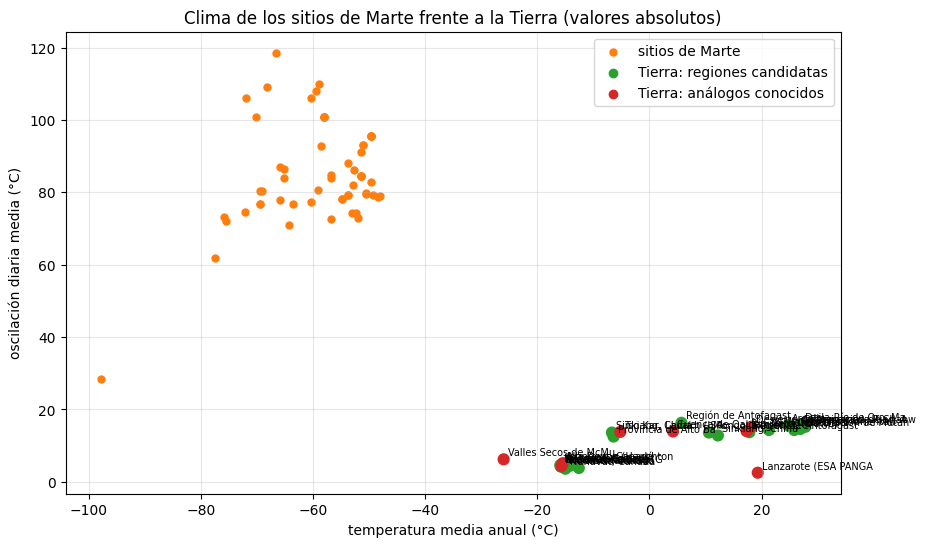

In [20]:
if len(pares):
    an = pares[pares.tipo_tierra == "analogo_conocido"]
    resumen_an = (an.sort_values("distancia_clima").groupby("region")
                  .agg(sitio_mas_parecido_clima=("sitio", "first"), distancia_clima=("distancia_clima", "first"),
                       sitios_parecidos_clima=("distancia_clima", lambda v: int((v <= UMBRAL_PARECIDO).sum())))
                  .sort_values("distancia_clima"))
    resumen_an = resumen_an.join(tierra.set_index("region")[["t_media", "t_min", "osc_diaria", "precip_mm"]])
    resumen_an.to_csv(f"{RES}/analogos_marte_clima.csv")
    display(resumen_an)

    # Valores absolutos: cuánto más frío es Marte que su pareja de la Tierra
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.scatter(t_m.t_media, t_m.osc_diaria, c=np.where(t_m.tipo == "analogo_conocido", "tab:red", "tab:green"), s=60)
    for r in t_m.itertuples():
        ax.annotate(str(r.region)[:20], (r.t_media, r.osc_diaria), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.scatter(clima_m.t_media, clima_m.osc_diaria, c="tab:orange", s=25, label="sitios de Marte")
    ax.scatter([], [], c="tab:green", label="Tierra: regiones candidatas"); ax.scatter([], [], c="tab:red", label="Tierra: análogos conocidos")
    ax.set_xlabel("temperatura media anual (°C)"); ax.set_ylabel("oscilación diaria media (°C)"); ax.grid(alpha=0.3); ax.legend()
    ax.set_title("Clima de los sitios de Marte frente a la Tierra (valores absolutos)")
    plt.show()

## 7. Capa para la web y registro

In [21]:
def limpio(v):
    if isinstance(v, (float, np.floating)): return None if np.isnan(v) else round(float(v), 3)
    if isinstance(v, np.integer): return int(v)
    return v

TERMINADO = not FALTAN_M2 and not FALTAN_MARTE
salida = {"version": VERSION,
          "unidades": {"temperaturas": "°C", "amplitud_anual y osc_diaria": "°C (K)", "precip_mm": "mm/año", "presion_pa": "Pa",
                       "distancias": "0–1, menor es más parecido (clima: diferencia media de percentiles)"},
          "tierra": {r["region_id"]: {k: limpio(v) for k, v in r.items() if k != "region_id"} for r in tierra.to_dict("records")},
          "marte_sitios": {}}
if len(pares):
    top = pares.groupby("sitio_id").head(5)
    for r in clima_m.to_dict("records"):
        salida["marte_sitios"][r["id"]] = {**{k: limpio(v) for k, v in r.items() if k != "id"},
            "top5_tierra": [{k: limpio(v) for k, v in p.items() if k in ("region_id", "region", "tipo_tierra", "distancia_clima",
                             "distancia_topografia", "distancia_total")} for p in top[top.sitio_id == r["id"]].to_dict("records")]}
json.dump(salida, open(f"{WEB}/clima.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2, allow_nan=False)
if TERMINADO:
    entrada = json.load(open(f"{BASE}/06_web/manifest.json", encoding="utf-8"))
    entrada.setdefault("capas", {})["clima"] = {"version": VERSION, "carpeta": VERSION, "archivo": f"{VERSION}/clima.json"}
    json.dump(entrada, open(f"{BASE}/06_web/manifest.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
registro = {"version": VERSION, "fecha": datetime.datetime.now().isoformat(timespec="seconds"),
            "datos": {"tierra": "NASA MERRA-2 2014–2023: clima de EDA_analogos_v1.3 (M2TMNXSLV, M2TMNXFLX) y M2SMNXSLV (T2MMAX, T2MMIN)",
                      "marte": "MACDA v2.0 (reanálisis MGS/TES y MRO/MCS; Valeanu, Rajendran, Montabone, Read et al.) en ARCO-Mars, Hugging Face: " + MACDA},
            "parametros": {"anios": [min(ANIOS), max(ANIOS)], "gradiente_k_km": GRADIENTE_K_KM, "anios_marte": list(ANIOS_MARTE), "medidas_comparacion": MEDIDAS, "umbral_parecido": UMBRAL_PARECIDO},
            "progreso": {"merra2_meses_faltan": len(FALTAN_M2), "macda_trozos_faltan": len(FALTAN_MARTE)},
            "limitaciones": ["MERRA-2 a ~50 km: un análogo pequeño (un valle, un cráter) recibe el clima de toda la celda, corregido solo por altitud",
                             "la comparación es relativa (percentiles): Marte es mucho más frío que cualquier lugar de la Tierra",
                             "Marte: temperatura de la superficie (MACDA no da la del aire a 2 m) frente a la del aire a 2 m en la Tierra; por eso se comparan percentiles",
                             "Marte en celdas de 5° (unos 300 km): un cráter o un valle recibe el clima de toda la celda",
                             "muestreo cada 2 horas: la máxima y la mínima diarias pueden quedarse algo cortas",
                             "la Mars Climate Database no respondió desde Colab el 26-10-2026; se sustituyó por MACDA",
                             "la Luna no tiene clima: no se compara"]}
json.dump(registro, open(f"{RES}/registro_{VERSION}.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
print("✅ Terminado y registrado en el manifest." if TERMINADO else "⏸ Guardado parcial: vuelve a ejecutar el notebook para completar.")

✅ Terminado y registrado en el manifest.


## 8. Conclusiones
# Clima v0: cierre (27 oct 2026)

Notebook: `clima_v0.1.ipynb` (genera la capa `clima_v0`). Completo: 120/120 meses de MERRA-2 y todos los trozos de MACDA.

## Datos
- Tierra: clima MERRA-2 2014–2023 de `EDA_analogos_v1.3` + M2SMNXSLV (máximas y mínimas diarias). Corrección por altitud −6,5 °C/km con la altura real de topografia_v1 (Mauna Kea −15,6 °C).
- Marte: MACDA v2.0 en ARCO-Mars (Hugging Face, Zarr), temperatura de la superficie cada 2 h, celdas de 5°, años marcianos 29–33. La Mars Climate Database no respondía desde Colab (timeout por https y http).
- Luna: no se compara (sin atmósfera).

## Método
- Percentiles relativos dentro de cada planeta en 4 medidas: temperatura media, mínima del mes más frío, amplitud anual, oscilación diaria. Distancia de clima = media de las diferencias de percentil.
- Distancia total = media de clima y topografía (topografia_sitios_v1). Parecido si ≤ 0,2.

## Resultados
- 42/59 sitios de Marte con pareja en la Tierra (solo topografía: 52/59).
- Mejores: Jezero ↔ Atacama 0,062 (clima 0,056, topografía 0,068); S. Meridiani Planum ↔ Argelia 0,082; E. Hellas 2 ↔ Nunavut 0,086; Newton Crater ↔ Isla Devon (Haughton) 0,102; Perseverance ↔ Antofagasta 0,104.
- Sin pareja: las llanuras más lisas (Viking 1, InSight, Phoenix, Tianwen-1, Arcadia ×2, Erebus, Zephyria), por el suelo de relieve de ASTER; también Rosalind Franklin (0,219), Cerberus, Ismenius, Noachis, Copernicus.
- Validación: los 8 análogos de Marte se parecen por clima al menos a un sitio. Lanzarote ↔ Pathfinder 0,029; Atacama ↔ Perseverance 0,056; Devon ↔ Newton 0,058; Río Tinto ↔ InSight 0,062; Qaidam ↔ S. Nectaris 0,066; Axel Heiberg ↔ E. Hellas 2 0,070; Tso Kar ↔ Apollinaris 0,072; McMurdo ↔ Deuteronilus 2 0,17. Axel Heiberg y McMurdo, que no encajaban por topografía, sí encajan por clima.

## Archivos
- 04_resultados/clima_v0/: clima_tierra.csv, clima_marte_sitios.csv, similitud_clima_marte.csv, clima_topografia_sitios_marte.csv, analogos_marte_clima.csv
- 06_web/clima_v0/clima.json (registrado en el manifest como capa clima)
- Bibliografía actualizada: M2SMNXSLV, MACDA/ARCO-Mars, incidencia de la MCD.

## Siguiente
- 27 oct: estructurar el flujo de trabajo de la aplicación web.
- 28 oct: datos oficiales del reto; decidir enfoque (índice por perfil o comparación por sitio).